# Import Library

In [183]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_rows', None)

# Inspeksi Awal Dataset

In [184]:
df = pd.read_csv('Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv')

In [185]:
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [186]:
df.tail()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
225740,61374,61,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225741,61378,72,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225742,61375,75,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225743,61323,48,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225744,61326,68,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [187]:
df.sample(5)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
103648,49531,80656311,7,9,11607,62,5840,0,1658.142857,2127.597740,...,20,38988.0,0.0,38988,38988,40300000.0,48500000.0,74600000,6011580,BENIGN
132507,80,91646331,8,6,56,11607,20,0,7.000000,5.656854,...,20,4077906.0,0.0,4077906,4077906,85900000.0,0.0,85900000,85900000,DDoS
151473,80,200560,3,6,26,11601,20,0,8.666667,10.263203,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
193471,38107,49,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
143312,80,175194,3,5,26,11607,20,0,8.666667,10.263203,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS


In [188]:
print("Jumlah baris: ", df.shape[0])
print("Jumlah kolom: ", df.shape[1])

Jumlah baris:  225745
Jumlah kolom:  79


In [189]:
print("nama kolom: ", df.columns.tolist())

nama kolom:  [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count'

In [190]:
# Membersihkan spasi di awal/akhir nama kolom
df.columns = df.columns.str.strip()

In [191]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 79 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             225745 non-null  int64  
 1   Flow Duration                225745 non-null  int64  
 2   Total Fwd Packets            225745 non-null  int64  
 3   Total Backward Packets       225745 non-null  int64  
 4   Total Length of Fwd Packets  225745 non-null  int64  
 5   Total Length of Bwd Packets  225745 non-null  int64  
 6   Fwd Packet Length Max        225745 non-null  int64  
 7   Fwd Packet Length Min        225745 non-null  int64  
 8   Fwd Packet Length Mean       225745 non-null  float64
 9   Fwd Packet Length Std        225745 non-null  float64
 10  Bwd Packet Length Max        225745 non-null  int64  
 11  Bwd Packet Length Min        225745 non-null  int64  
 12  Bwd Packet Length Mean       225745 non-null  float64
 13 

In [192]:
df.describe()

c:\Users\Mirwan Qolyubi\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\Mirwan Qolyubi\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,225745.00000,2.257450e+05,225745.000000,225745.000000,225745.000000,2.257450e+05,225745.000000,225745.000000,225745.000000,225745.000000,...,225745.000000,225745.000000,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05
mean,8879.61946,1.624165e+07,4.874916,4.572775,939.463346,5.960477e+03,538.535693,27.882221,164.826715,214.907242,...,3.311497,21.482753,1.848261e+05,1.293436e+04,2.080849e+05,1.776201e+05,1.032214e+07,3.611943e+06,1.287813e+07,7.755355e+06
std,19754.64740,3.152437e+07,15.422874,21.755356,3249.403484,3.921834e+04,1864.128991,163.324159,504.892965,797.411073,...,12.270018,4.166799,7.979250e+05,2.102737e+05,9.002350e+05,7.842602e+05,2.185303e+07,1.275689e+07,2.692126e+07,1.983109e+07
min,0.00000,-1.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,80.00000,7.118000e+04,2.000000,1.000000,26.000000,0.000000e+00,6.000000,0.000000,6.000000,0.000000,...,1.000000,20.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,80.00000,1.452333e+06,3.000000,4.000000,30.000000,1.640000e+02,20.000000,0.000000,8.666667,5.301991,...,2.000000,20.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,80.00000,8.805237e+06,5.000000,5.000000,63.000000,1.160100e+04,34.000000,6.000000,32.000000,10.263203,...,4.000000,20.000000,1.878000e+03,0.000000e+00,1.878000e+03,1.862000e+03,8.239725e+06,0.000000e+00,8.253838e+06,7.422849e+06
max,65532.00000,1.199999e+08,1932.000000,2942.000000,183012.000000,5.172346e+06,11680.000000,1472.000000,3867.000000,6692.644993,...,1931.000000,52.000000,1.000000e+08,3.950000e+07,1.000000e+08,1.000000e+08,1.200000e+08,6.530000e+07,1.200000e+08,1.200000e+08


In [193]:
df['Label'].value_counts()

Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

In [194]:
print("Data duplikat: ", df.duplicated().sum())

Data duplikat:  2633


In [195]:
print("Data missing: ", df.isnull().sum().sum())

Data missing:  4


In [196]:
df.nunique()

Destination Port                23950
Flow Duration                  187752
Total Fwd Packets                 297
Total Backward Packets            367
Total Length of Fwd Packets      3831
Total Length of Bwd Packets      6760
Fwd Packet Length Max            1891
Fwd Packet Length Min             151
Fwd Packet Length Mean           7401
Fwd Packet Length Std            9555
Bwd Packet Length Max            1945
Bwd Packet Length Min             343
Bwd Packet Length Mean           8655
Bwd Packet Length Std            9650
Flow Bytes/s                   202293
Flow Packets/s                 194094
Flow IAT Mean                  193666
Flow IAT Std                   159622
Flow IAT Max                   139745
Flow IAT Min                    11093
Fwd IAT Total                   78049
Fwd IAT Mean                    95095
Fwd IAT Std                     91184
Fwd IAT Max                     77978
Fwd IAT Min                      8820
Bwd IAT Total                  101942
Bwd IAT Mean

In [197]:
# Mengecek apakah ada nilai tak hingga (infinity) dalam DataFrame
np.isinf(df.select_dtypes(include=np.number)).sum()

Destination Port                0
Flow Duration                   0
Total Fwd Packets               0
Total Backward Packets          0
Total Length of Fwd Packets     0
Total Length of Bwd Packets     0
Fwd Packet Length Max           0
Fwd Packet Length Min           0
Fwd Packet Length Mean          0
Fwd Packet Length Std           0
Bwd Packet Length Max           0
Bwd Packet Length Min           0
Bwd Packet Length Mean          0
Bwd Packet Length Std           0
Flow Bytes/s                   30
Flow Packets/s                 34
Flow IAT Mean                   0
Flow IAT Std                    0
Flow IAT Max                    0
Flow IAT Min                    0
Fwd IAT Total                   0
Fwd IAT Mean                    0
Fwd IAT Std                     0
Fwd IAT Max                     0
Fwd IAT Min                     0
Bwd IAT Total                   0
Bwd IAT Mean                    0
Bwd IAT Std                     0
Bwd IAT Max                     0
Bwd IAT Min   

# Data Cleaning

In [198]:
# Menghapus baris duplikat
df = df.drop_duplicates()
print("Data duplikat setelah penghapusan: ", df.duplicated().sum())

Data duplikat setelah penghapusan:  0


In [199]:
# Mengganti nilai tak hingga (infinity) dengan NaN
kolom_numerik = df.select_dtypes(include=[np.number]).columns
df[kolom_numerik] = df[kolom_numerik].replace([np.inf, -np.inf], np.nan)
print("Jumlah nilai NaN setelah penggantian: ", df.isnull().sum().sum())

Jumlah nilai NaN setelah penggantian:  60


In [200]:
# Inputasi nilai NaN dengan median kolom
df[kolom_numerik] = df[kolom_numerik].fillna(df[kolom_numerik].median())
print("Jumlah nilai NaN setelah inputasi: ", df.isnull().sum().sum())

Jumlah nilai NaN setelah inputasi:  0


# Exploratory Data Analysis

Label
DDoS      128016
BENIGN     95096
Name: count, dtype: int64
Label
DDoS      57.38
BENIGN    42.62
Name: count, dtype: float64


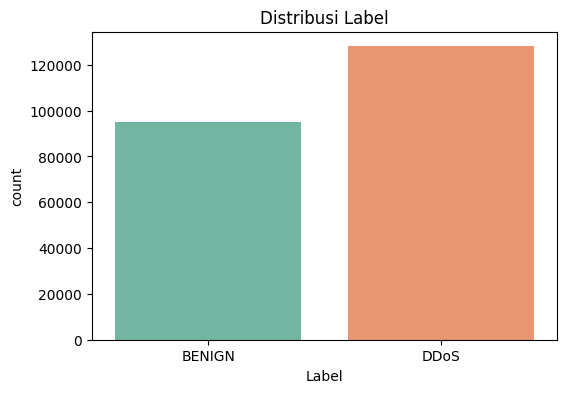

In [201]:
counts = df['Label'].value_counts()
print(counts)
print((counts / counts.sum() * 100).round(2))

plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Label', hue='Label', palette='Set2', legend=False)
plt.title('Distribusi Label')
plt.show()

In [202]:
fitur_kunci = ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
               'Flow Bytes/s', 'Flow Packets/s', 'Packet Length Mean',
               'Average Packet Size', 'Fwd IAT Mean']
df.groupby('Label')[fitur_kunci].mean().T

Label,BENIGN,DDoS
Flow Duration,1.572826e+07,1.695689e+07
Total Fwd Packets,5.487928e+00,4.472628e+00
Total Backward Packets,6.436306e+00,3.256046e+00
Flow Bytes/s,1.215056e+06,6.050896e+04
Flow Packets/s,3.002537e+04,1.553864e+02
Packet Length Mean,2.293020e+02,7.369410e+02
Average Packet Size,2.549818e+02,8.226713e+02
Fwd IAT Mean,2.456880e+06,2.655012e+06


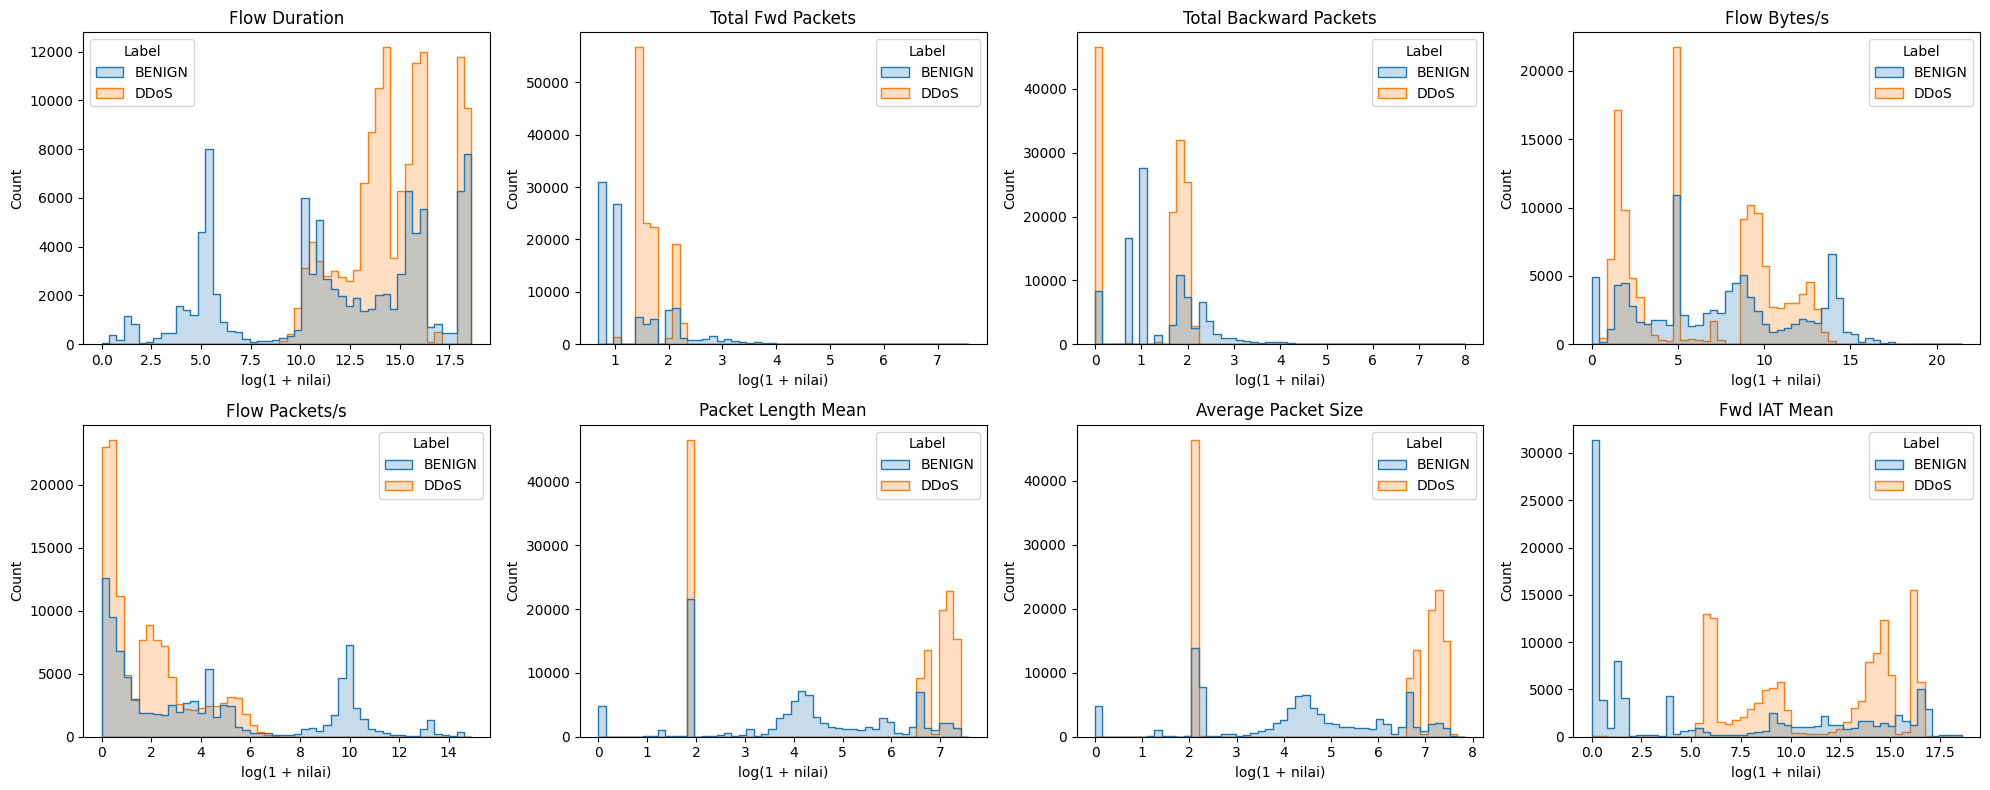

In [203]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), fitur_kunci):
    sns.histplot(x=np.log1p(df[col].clip(lower=0)), hue=df['Label'],
                 bins=50, ax=ax, element='step')
    ax.set_title(col)
    ax.set_xlabel('log(1 + nilai)')
plt.tight_layout()
plt.show()

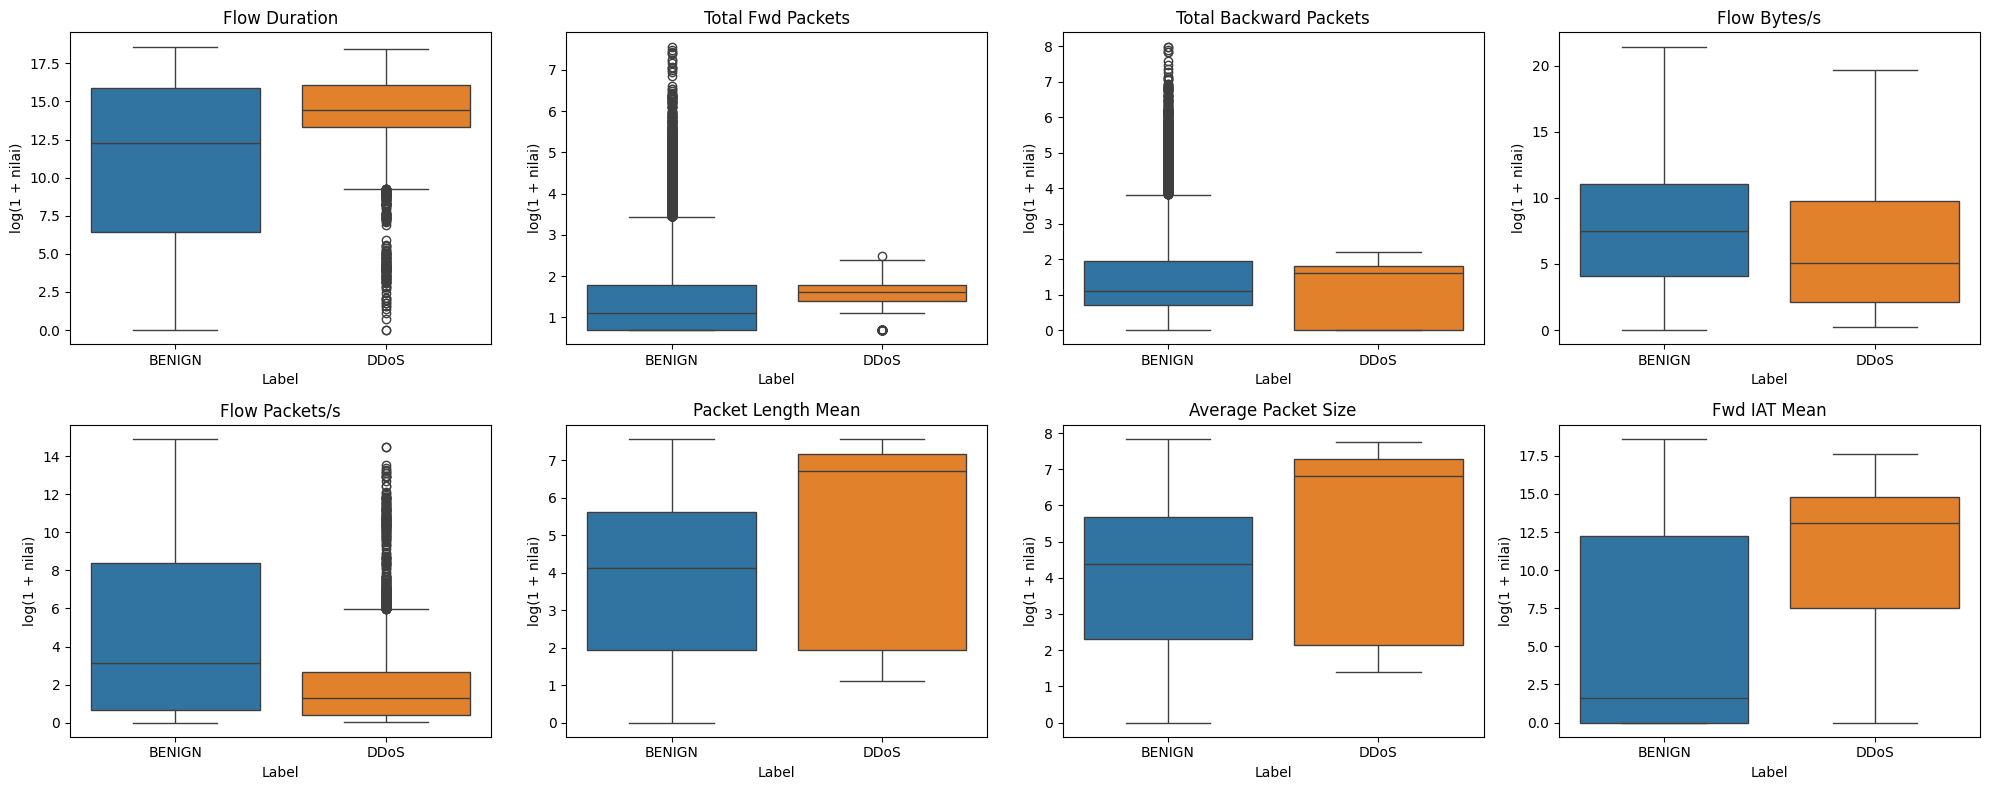

In [204]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), fitur_kunci):
    sns.boxplot(x=df['Label'], y=np.log1p(df[col].clip(lower=0)), hue=df['Label'], ax=ax, legend=False)
    ax.set_title(col)
    ax.set_ylabel('log(1 + nilai)')
plt.tight_layout()
plt.show()

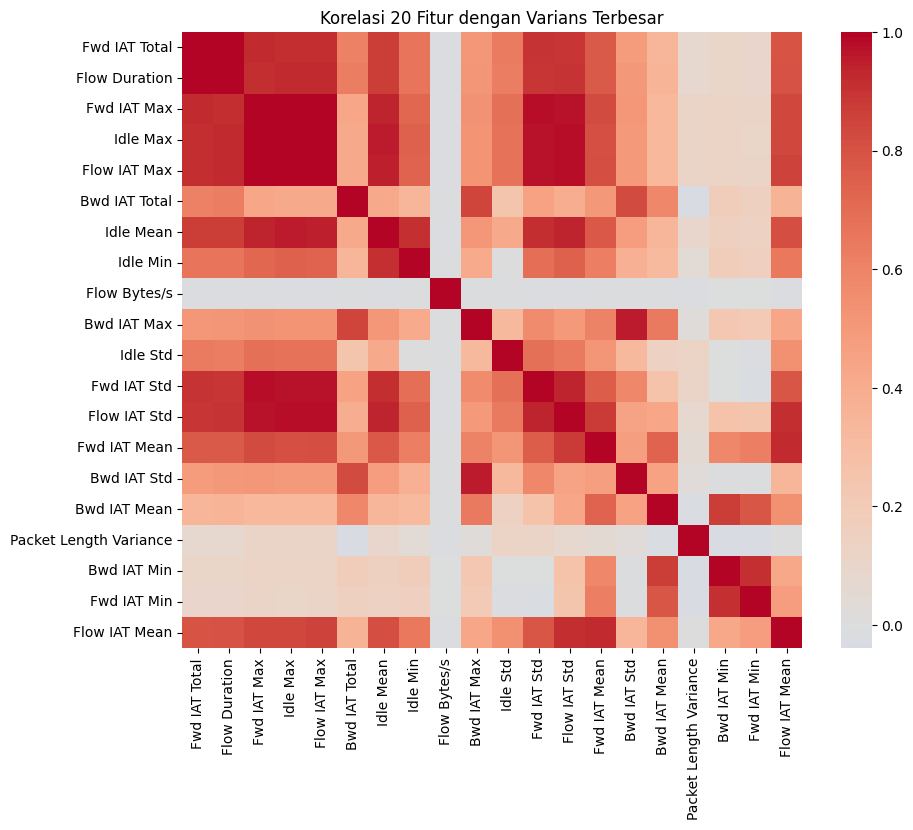

In [205]:
# Buang kolom konstan agar korelasi tidak NaN
num = df.select_dtypes(include=np.number)
num = num.loc[:, num.nunique() > 1]

top_cols = num.var().sort_values(ascending=False).head(20).index
plt.figure(figsize=(10, 8))
sns.heatmap(num[top_cols].corr(), cmap='coolwarm', center=0)
plt.title('Korelasi 20 Fitur dengan Varians Terbesar')
plt.show()

Bwd Packet Length Mean    0.599953
Avg Bwd Segment Size      0.599953
Bwd Packet Length Max     0.573842
Bwd Packet Length Std     0.572767
Destination Port         -0.520359
URG Flag Count           -0.472124
Packet Length Mean        0.448314
Average Packet Size       0.447614
Packet Length Std         0.437712
Min Packet Length        -0.422650
Max Packet Length         0.408094
min_seg_size_forward     -0.406140
Packet Length Variance    0.403211
Fwd Packet Length Mean   -0.363551
Avg Fwd Segment Size     -0.363551
dtype: float64


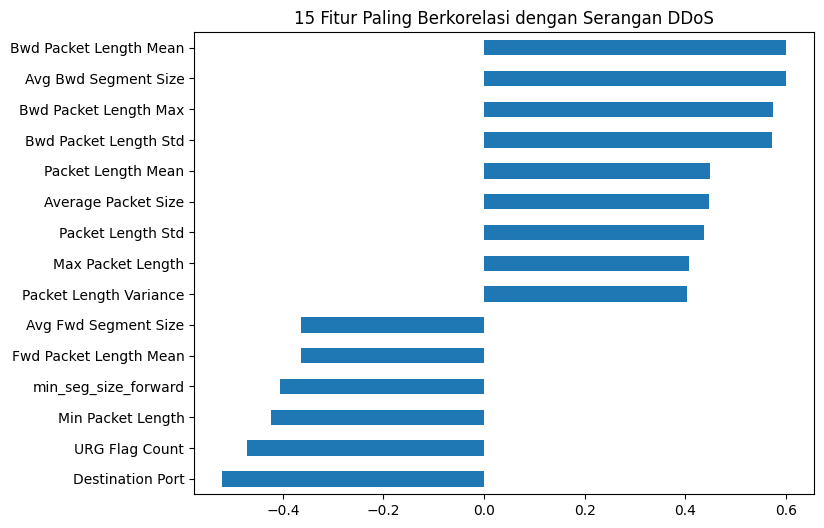

In [206]:
y = (df['Label'] != 'BENIGN').astype(int)
corr_label = num.corrwith(y).dropna().sort_values(key=abs, ascending=False)
print(corr_label.head(15))

plt.figure(figsize=(8, 6))
corr_label.head(15).sort_values().plot(kind='barh')
plt.title('15 Fitur Paling Berkorelasi dengan Serangan DDoS')
plt.show()

In [207]:
Q1, Q3 = num.quantile(0.25), num.quantile(0.75)
IQR = Q3 - Q1
outlier_pct = (((num < Q1 - 1.5*IQR) | (num > Q3 + 1.5*IQR)).mean() * 100).sort_values(ascending=False)
outlier_pct.head(10).round(2)

Destination Port               38.79
Flow Bytes/s                   20.01
Active Mean                    19.57
Active Max                     19.57
Active Min                     19.53
Bwd Packets/s                  17.71
Flow Packets/s                 17.46
Fwd Packets/s                  17.34
Flow Duration                  16.77
Total Length of Fwd Packets    16.75
dtype: float64